In [15]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [23]:
url = 'https://github.com/git-iush/large_family/raw/refs/heads/main/data2.parquet'
df = pd.read_parquet(url)

In [24]:
df.head()

,SERIAL,HHWT,CLUSTER,STRATA,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,...,BLACK,AIAN,API,OTHER,MULTR,HISP,EXPANSION,WELFARE,PRSNINC,YRSEDUC
0,4,4.0,2024000000041,280201,1,4.0,0,2,22,6,...,0,0,1,0,0,0,0,0.0,1000.0,13
1,9,74.0,2024000000091,280301,1,74.0,0,2,18,6,...,1,0,0,0,0,0,0,0.0,5100.0,12
2,12,55.0,2024000000121,160001,1,55.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,0.0,12
3,15,17.0,2024000000151,120201,1,17.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,6000.0,12
4,19,71.0,2024000000191,10001,1,71.0,0,2,23,6,...,0,0,0,0,0,0,0,0.0,0.0,13


In [25]:
#variable tweak
df['MEDICAID'] = df['HINSCAID'] - 1
df['FAMINC'] = df['FTOTINC'] - df['INCTOT']
#codes 1-3 in IPUMS are women who are still legally married so that's 1-3 is 1 for married and 0 is not
df['MARD'] = [1 if i <= 3 else 0 for i in df['MARST']]

In [27]:
#left edu statess and race out
df = df[['NCHILD', 'MEDICAID', 'WELFARE', 'AGE', 'PRSNINC', 'FAMINC', 'MARD']]
df.dropna(inplace=True)
df.shape

(678476, 7)

In [29]:
#some terms are squared and separated welfare and medicaid for variables like age for the pooled regression
df['AGE2'] = df['AGE']**2
df['PRSNINC2'] = df['PRSNINC']**2
df['FAMINC2'] = df['FAMINC']**2
df['MEDFARE'] = df['MEDICAID'] * df['WELFARE']
df['MEDICAGE'] = df['MEDICAID'] * df['AGE']
df['MEDICAGE2'] = df['MEDICAID'] * df['AGE2']
df['WELFAGE'] = df['WELFARE'] * df['AGE']
df['WELFAGE2'] = df['WELFARE'] * df['AGE2']
df['MEDFARAGE'] = df['MEDFARE'] * df['AGE']
df['MEDFARAGE2'] = df['MEDFARE'] * df['AGE2']

In [20]:
pred = smf.ols('NCHILD ~ MEDICAID + WELFARE + MEDFARE + MEDICAGE + MEDICAGE2 + WELFAGE + WELFAGE2 + MEDFARAGE + MEDFARAGE2 + AGE + AGE2 + PRSNINC + PRSNINC2 + FAMINC + FAMINC2 + MARD', data=df).fit()
print(pred.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.310
Model:                            OLS   Adj. R-squared:                  0.310
Method:                 Least Squares   F-statistic:                 1.904e+04
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:47:46   Log-Likelihood:            -9.6964e+05
No. Observations:              678476   AIC:                         1.939e+06
Df Residuals:                  678459   BIC:                         1.940e+06
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2475      0.016   -136.911      0.0

In [21]:
#Counting women ages 15-50
ages = [i for i in range(15, 50)]

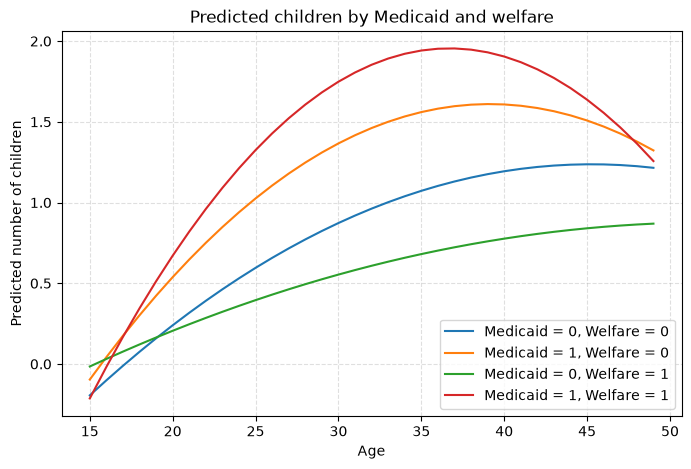

In [43]:
plt.figure(figsize=(8, 5))

#running a loop for the pooled
for m, w in zip([0, 1, 0, 1], [0, 0, 1, 1]):
    new = pd.DataFrame({'AGE': ages,
                        'MEDICAID': [m for i in ages],
                        'WELFARE': [w for i in ages],
                        #holding at the mean far MED and WEL effect
                        'PRSNINC': [df['PRSNINC'].mean() for i in ages],
                        'FAMINC': [df['FAMINC'].mean() for i in ages],
                        'MARD': [df['MARD'].mean() for i in ages]})

   #same interaction terms for the model
    new['AGE2'] = new['AGE']**2
    new['PRSNINC2'] = new['PRSNINC']**2
    new['FAMINC2'] = new['FAMINC']**2
    new['MEDFARE'] = new['MEDICAID'] * new['WELFARE']
    new['MEDICAGE'] = new['MEDICAID'] * new['AGE']
    new['MEDICAGE2'] = new['MEDICAID'] * new['AGE2']
    new['WELFAGE'] = new['WELFARE'] * new['AGE']
    new['WELFAGE2'] = new['WELFARE'] * new['AGE2']
    new['MEDFARAGE'] = new['MEDFARE'] * new['AGE']
    new['MEDFARAGE2'] = new['MEDFARE'] * new['AGE2']

    plt.plot(ages, pred.predict(new), label=f'Medicaid = {m}, Welfare = {w}')

plt.xlabel('Age')

plt.ylabel('Predicted number of children')

plt.title('Predicted children by Medicaid and welfare')

plt.legend()

plt.grid(alpha=0.4, ls='--')

plt.show()